# SketchRAG demo: streaming sketches as retrieval memory

**Team:** Ranjith Kumar (2023BCD0030), Bhuvan S M (2023BCS0198), Nooh K (2023BCD0003), Hariprasanth (2023BCS0036)

An agent reading an unbounded stream cannot keep and search every chunk. SketchRAG keeps a **bounded hot memory**
(semantic cells, per-cell Count-Min Sketches, Misra-Gries heavy hitters, short extractive digests) and puts the raw chunks in
**cold storage**. At question time, an **error-bound gate** decides which cells' digests can be trusted and which must be
read raw.

This notebook walks through it on real test questions:

1. The two sketches on their own, and their error guarantees
2. Streaming a long document into bounded memory
3. Looking inside the memory
4. Three questions: the gate stays closed, fires on a lossy digest, fires on an exact key
5. The full results (350 questions, qwen2.5:7b-instruct)

Steps 1 to 4 need no LLM. Answers shown as *saved* are the recorded qwen2.5:7b-instruct answers from the main Kaggle run.
Set `RUN_LIVE = True` to also ask a local Ollama model.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "demo"))

import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

import demo_core as d
from sketchrag.sketches.countmin import CountMinSketch
from sketchrag.sketches.misra_gries import MisraGries

pd.set_option("display.max_colwidth", 120)
RUN_LIVE = False          # True: also ask the local Ollama model (about 40 s per answer on this CPU)
LIVE_MODEL = "llama3.2:3b"

## 1. The sketches on their own

**Count-Min Sketch** (width *w*, depth *d*) never under-counts, and over-counts by at most ε·N with ε = e/w,
with probability at least 1 − e^(−d). **Misra-Gries** with *k* counters finds every term with frequency above N/(k+1).
Both are hand-written in `src/sketchrag/sketches/` and unit-tested. Here they run on a Zipf-distributed stream of 200,000 tokens.

In [2]:
rng = np.random.default_rng(0)
stream_tokens = [f"t{x}" for x in rng.zipf(1.3, 200_000) if x < 50_000]
true = Counter(stream_tokens)

cms = CountMinSketch(width=512, depth=3)
mg = MisraGries(k=64)
for t in stream_tokens:
    cms.update(t)
    mg.update(t)

N = len(stream_tokens)
over = np.array([cms.query(t) - c for t, c in true.items()])
print(f"stream length N = {N:,}, distinct terms = {len(true):,}")
print(f"CMS memory: {cms.nbytes / 1024:.0f} KB for {len(true):,} distinct terms")
print(f"never under-counts: {bool((over >= 0).all())}")
print(f"eps*N bound = {cms.error_bound():.0f};  terms over the bound: {(over > cms.error_bound()).mean():.2%} "
      f"(guarantee: at most {cms.delta:.1%})")

top_true = [t for t, _ in true.most_common(10)]
top_mg = [t for t, _ in mg.top(10)]
print("\ntrue top 10:        ", top_true)
print("Misra-Gries top 10: ", top_mg)
print("overlap:", len(set(top_true) & set(top_mg)), "/ 10")

stream length N = 193,429, distinct terms = 9,853
CMS memory: 6 KB for 9,853 distinct terms
never under-counts: True
eps*N bound = 1027;  terms over the bound: 0.03% (guarantee: at most 5.0%)

true top 10:         ['t1', 't2', 't3', 't4', 't5', 't6', 't7', 't8', 't9', 't10']
Misra-Gries top 10:  ['t1', 't2', 't3', 't4', 't5', 't6', 't7', 't8', 't9', 't10']
overlap: 10 / 10


## 2. Stream a long document into bounded memory

A NarrativeQA story (about 28k words) arrives as 150-word chunks. Each chunk joins its nearest cell or opens a new one.
When there are more than 64 cells, the closest pair is merged (Ward linkage). The hot memory stops growing once
the cap is reached; cold storage keeps every raw chunk.

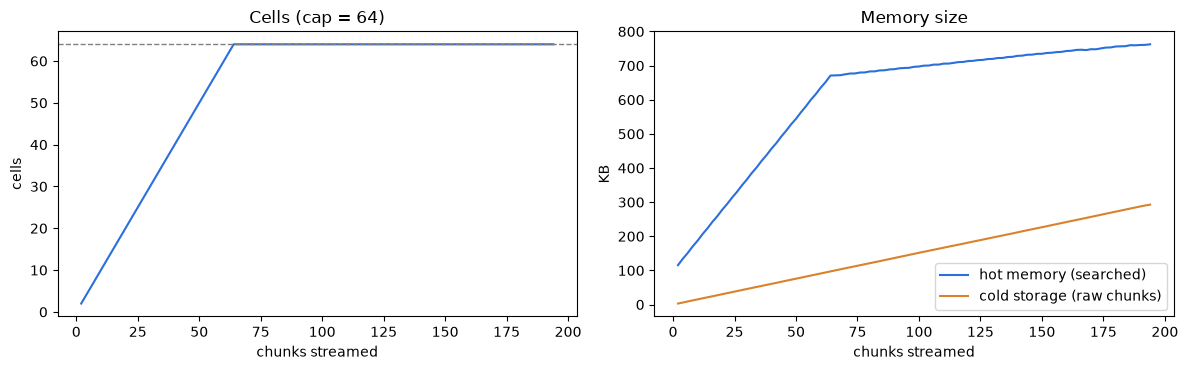

194 chunks -> 64 cells after 109 merges; ingest 2.9 ms/chunk


In [3]:
ex = d.find_example("narrativeqa/a5e44b1e2b98f80aabab5f1b8296d0fe66d53b31c1f3e332")
chunks, embs = d.chunk_and_embed(ex)          # bge-small embeddings, cached from the experiments
mem, trace = d.stream(chunks, embs, every=2)
tr = pd.DataFrame(trace)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(tr.chunks, tr.cells, color="#2a6fdb")
ax[0].axhline(64, ls="--", color="grey", lw=1)
ax[0].set(title="Cells (cap = 64)", xlabel="chunks streamed", ylabel="cells")
ax[1].plot(tr.chunks, tr.hot_kb, label="hot memory (searched)", color="#2a6fdb")
ax[1].plot(tr.chunks, tr.cold_kb, label="cold storage (raw chunks)", color="#d9822b")
ax[1].set(title="Memory size", xlabel="chunks streamed", ylabel="KB")
ax[1].legend()
plt.tight_layout()
plt.show()
s = mem.stats()
print(f"{s['n_chunks']} chunks -> {s['n_cells']} cells after {s['n_merges']} merges; "
      f"ingest {tr.ms.iloc[-1] / s['n_chunks']:.1f} ms/chunk")

After the cap, hot memory only creeps up until every cell's digest (120 words) and exemplar set (8 embeddings)
is full; that ceiling is fixed by the configuration, not by the stream length. On one short document it is
still larger than the raw text, because sketch tables and exemplar embeddings dominate. The bound pays off on
long streams. In our 8.5M-word stress test, hot memory
stayed at 1 to 4 MB while a dense index needed 146 MB:

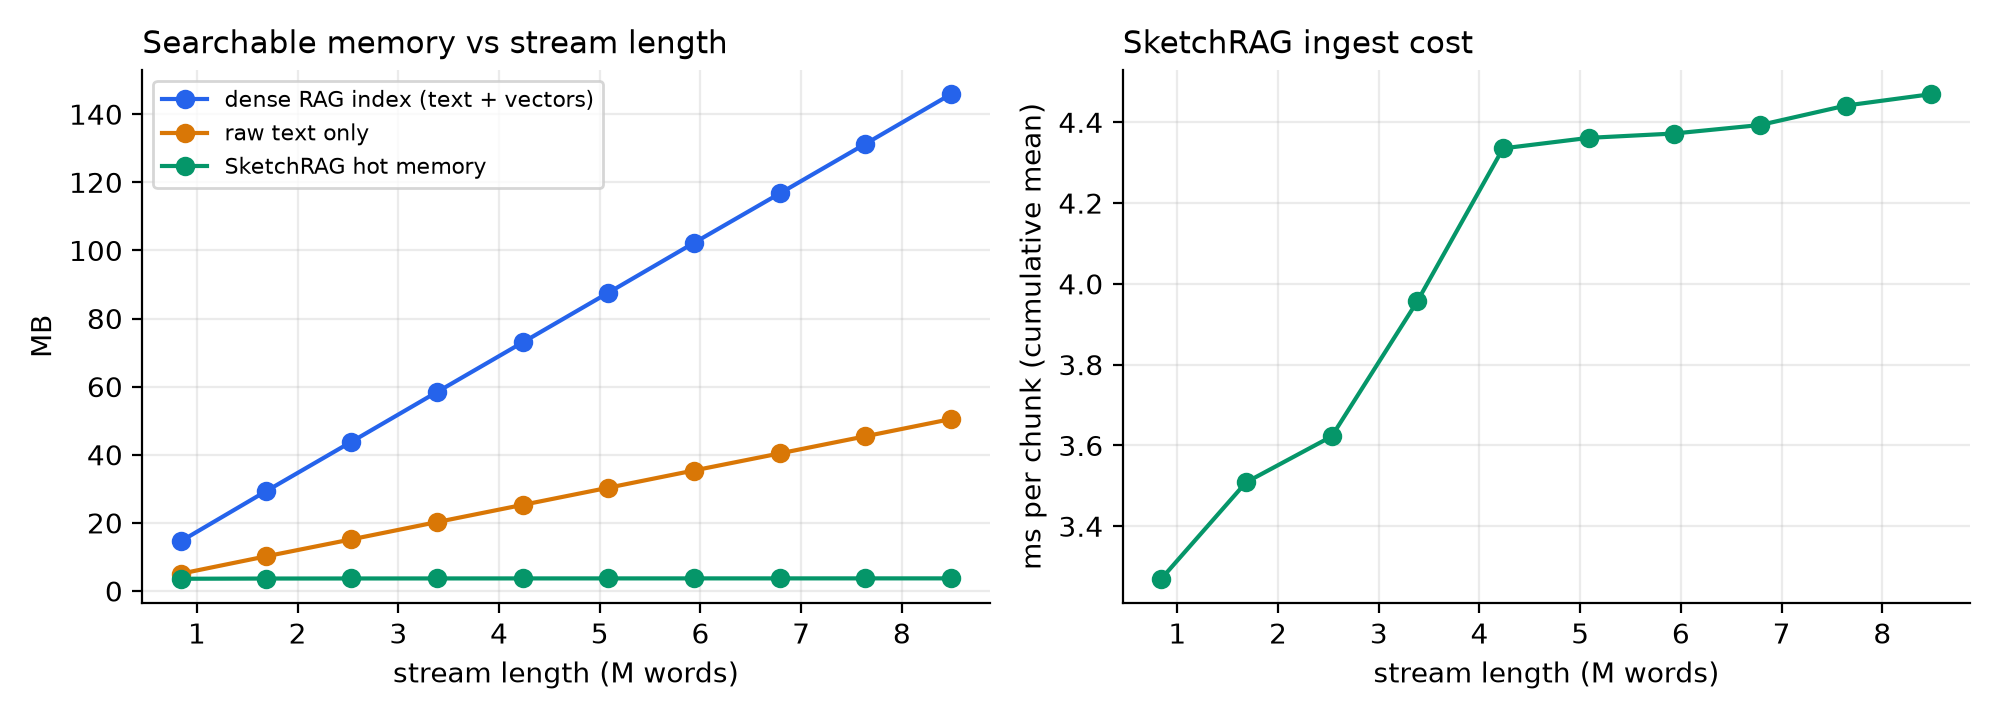

In [4]:
display(Image(filename=str(d.ROOT / "report" / "figures" / "stress_memory.png"), width=720))

## 3. Inside the memory

Each cell keeps its time span, size, radius (how spread out its chunks are) and a digest of at most 120 words.
The global Misra-Gries table gives the stream's topics.

In [5]:
print("Stream topics (Misra-Gries heavy hitters):", ", ".join(t for t, _ in mem.mg.top(15)))
cells = pd.DataFrame(d.cells_table(mem))
cells["digest"] = cells["digest"].str.slice(0, 160) + "..."
cells.head(8)

Stream topics (Misra-Gries heavy hitters): baron, upon, otto, thou, little, hans, great, old, face, stood, man, conrad, back, bridge, father


,cell,positions,chunks,radius,digest words,digest
0,0,0-190,2,0.328,119,"Folks called him ""Otto of the Silver Hand,"" but perhaps there was another reason than that for the name that had bee..."
1,1,1-1,1,0.000,116,"Yet, though the world's life then was so wicked and black, there yet remained a few good men and women here and ther..."
2,2,2-183,3,0.412,113,"Sometimes the old Abbot would unlock the iron-bound chest where these treasures lay hidden, and carefully and loving..."
3,3,3-62,3,0.400,118,"Otto looked around upon the many faces gathered there to catch the first sight of the little baron; hard, rugged fac..."
4,5,5-5,1,0.000,120,"Within the massive stone walls through which the gaping gateway led, three great cheerless brick buildings, so forbi..."
5,6,6-6,1,0.000,113,"From the chimney of this crazy hut a thin thread of smoke would now and then rise into the air, for there were folk ..."
6,7,7-91,3,0.417,120,"Suddenly there was a movement in the shadow of the arch of the great gateway across the court-yard, and the next mom..."
7,8,8-9,2,0.375,120,Then would follow a great noise and uproar and hurry in the castle court-yard below; men shouting and calling to one...


## 4. The gate, question by question

For every retrieved cell, the gate checks each **rare** query term (idf ≥ 2.5) against the cell's Count-Min Sketch:

* **lossy**: the sketch says the term is in the cell (above the noise floor) but the digest dropped it
* **unresolved**: no retrieved cell holds the rare terms above the guaranteed ε·N bound, so the top two cells are read raw
* **loose**: the cell is too spread out for its digest to be faithful

Escalated cells have their digest replaced by their two most relevant raw chunks from cold storage.

In [6]:
def show(ex_id):
    case = next(c for c in d.SHOWCASE if c["id"] == ex_id)
    ex = d.find_example(ex_id)
    chunks, embs = d.chunk_and_embed(ex)
    mem, _ = d.stream(chunks, embs, every=len(chunks))
    q = d.embed_question(ex.question)
    g = d.explain_gate(mem, ex.question, q)
    ctx = d.contexts(mem, ex.question, q)

    display(Markdown(f"### {case['title']}\n{case['story']}\n\n"
                     f"**Question:** {ex.question.strip()[:300] or '(summarise the report)'}  \n"
                     f"**Gold answer:** {ex.answers[0][:200]}  \n"
                     f"**Document:** {len(ex.context.split()):,} words, {len(chunks)} chunks, {len(mem.cells)} cells"))
    print("rare query terms:", g["rare"] or "none (the gate has nothing to check)")
    display(pd.DataFrame(g["hit_rows"]).set_index("rank"))
    if g["term_rows"]:
        t = pd.DataFrame(g["term_rows"])
        display(t.pivot_table(index="term", columns="cell", values="CMS estimate", sort=False)
                 .style.set_caption("CMS estimate of each rare term in each retrieved cell"))
    for cid, why in g["decision"].reasons.items():
        print(f"  cell {cid}: {why} -> {d.REASON_TEXT[why]}")

    rows = []
    saved = d.saved_answers(ex.id)
    for policy, system in (("sketch", "sketchrag_sketch"), ("gate", "sketchrag_gate"), ("raw", "sketchrag_raw")):
        r = saved.get(system, {})
        rows.append({"system": d.SYSTEM_LABELS[system], "context words": ctx[policy]["words"],
                     "gold answer in context": bool(d.answer_in_context(ctx[policy]["context"], ex.answers)),
                     "saved answer (qwen2.5:7b)": r.get("pred", "")[:60], "score": r.get("score")})
    for system in ("full_context", "bm25_rag", "dense_rag"):
        r = saved.get(system, {})
        rows.append({"system": d.SYSTEM_LABELS[system], "context words": None, "gold answer in context": None,
                     "saved answer (qwen2.5:7b)": r.get("pred", "")[:60], "score": r.get("score")})
    display(pd.DataFrame(rows).set_index("system"))
    if RUN_LIVE:
        live = d.live_answer(ex, ctx["gate"]["context"], LIVE_MODEL)
        print(f"live {LIVE_MODEL} with the gated context: {live}")
    return ctx

### 4a. Summary is enough

In [7]:
ctx = show("hotpotqa/9336554e511e88766228ffa1acd1c6f82c9a41046514c253")

### Summary is enough (gate stays closed)
The digest already holds the answer, so the gate trusts the sketch and reads nothing raw.

**Question:** Who did Fredric Rieders tesify agains who had killed as many as 60 patients and recieved three consecutive life terms to be served in Florence Colorado?  
**Gold answer:** Michael Swango  
**Document:** 12,326 words, 95 chunks, 64 cells

rare query terms: ['fredric', 'rieders', 'tesify', 'agains', 'killed', 'many', '60', 'recieved', 'three', 'consecutive', 'life', 'terms', 'served', 'florence', 'colorado']


,cell,positions,chunks,similarity,radius,eps*N bound,noise N/w,gate
rank,,,,,,,,
1,26,27-27,1,0.688,0.000,0.5,0.17,trusted
2,25,26-28,2,0.661,0.300,0.8,0.31,trusted
3,72,74-74,1,0.632,0.000,0.4,0.16,trusted
4,57,59-62,2,0.603,0.328,0.8,0.31,trusted
5,28,29-37,2,0.463,0.323,0.9,0.34,trusted


cell,26,25,72,57,28
term,,,,,
fredric,1.000000,2.000000,0.000000,0.000000,0.000000
rieders,5.000000,4.000000,0.000000,0.000000,0.000000
tesify,0.000000,0.000000,0.000000,0.000000,0.000000
agains,0.000000,0.000000,0.000000,0.000000,0.000000
killed,2.000000,0.000000,0.000000,0.000000,0.000000
many,2.000000,0.000000,1.000000,0.000000,0.000000
60,1.000000,0.000000,1.000000,0.000000,0.000000
recieved,0.000000,0.000000,0.000000,0.000000,0.000000
three,0.000000,0.000000,1.000000,0.000000,0.000000


,context words,gold answer in context,saved answer (qwen2.5:7b),score
system,,,,
"SketchRAG, digest only",622.0,True,Michael Swango,1.0
SketchRAG + gate,622.0,True,Michael Swango,1.0
"SketchRAG, always raw",1164.0,True,Michael Swango,1.0
Full context,NaN,None,Michael Swango,1.0
BM25 RAG,NaN,None,Michael Swango,1.0
Dense RAG,NaN,None,Michael Swango,1.0


### 4b. Lossy digest

In [8]:
ctx = show("hotpotqa/1ceb1c91662d241b3421853112a91b5868d1b81fe3b88ce4")

### Lossy digest (gate fires: lossy)
The cell's Count-Min Sketch says the rare query terms are in the cell, but the digest dropped them, so the gate reads those cells' raw chunks.

**Question:** The large subunit and small subunit that use two types of RNA are major components that make up what?  
**Gold answer:** Ribosomes  
**Document:** 11,189 words, 89 chunks, 54 cells

rare query terms: ['large', 'subunit', 'small', 'use', 'types', 'major', 'components', 'make']


,cell,positions,chunks,similarity,radius,eps*N bound,noise N/w,gate
rank,,,,,,,,
1,17,28-28,1,0.731,0.0,0.4,0.16,trusted
2,46,77-77,1,0.728,0.0,0.4,0.16,trusted
3,43,67-73,7,0.716,0.4,2.9,1.06,lossy
4,42,66-66,1,0.713,0.0,0.4,0.16,trusted
5,18,29-31,3,0.628,0.3,1.3,0.49,lossy


cell,17,46,43,42,18
term,,,,,
large,5.000000,3.000000,8.000000,1.000000,2.000000
subunit,6.000000,6.000000,12.000000,1.000000,4.000000
small,3.000000,3.000000,4.000000,1.000000,4.000000
use,0.000000,0.000000,1.000000,0.000000,1.000000
types,0.000000,0.000000,0.000000,0.000000,0.000000
major,0.000000,0.000000,0.000000,0.000000,0.000000
components,0.000000,0.000000,1.000000,0.000000,0.000000
make,1.000000,0.000000,0.000000,0.000000,0.000000


  cell 43: lossy -> the sketch says a rare query term is in this cell but the digest dropped it
  cell 18: lossy -> the sketch says a rare query term is in this cell but the digest dropped it


,context words,gold answer in context,saved answer (qwen2.5:7b),score
system,,,,
"SketchRAG, digest only",635.0,True,ribosome,0.0
SketchRAG + gate,933.0,True,ribosomes,1.0
"SketchRAG, always raw",998.0,True,ribosomes,1.0
Full context,NaN,None,ribosome,0.0
BM25 RAG,NaN,None,Ribosomes,1.0
Dense RAG,NaN,None,ribosome,0.0


### 4c. Exact key lookup

In [9]:
ctx = show("kv_retrieval/130")

### Exact key lookup (gate fires: unresolved)
A UUID key never survives summarisation. No cell can vouch for it above the eps*N bound, so the gate reads raw evidence. Digest-only answers with a wrong fragment.

**Question:** Key: "35b9fdc1-c2c2-4d9a-8789-075cf4e06e99"
The value associated with the specified key is:  
**Gold answer:** e2e6376e-5c57-4b42-913a-349fc4573a57  
**Document:** 5,002 words, 219 chunks, 3 cells

rare query terms: ['key', '35b9fdc1', 'c2c2', '4d9a', '8789', '075cf4e06e99', 'value', 'associated', 'specified']


,cell,positions,chunks,similarity,radius,eps*N bound,noise N/w,gate
rank,,,,,,,,
1,2,2-218,217,0.692,0.347,132.1,48.60,unresolved
2,1,1-1,1,0.684,0.000,0.6,0.22,unresolved
3,0,0-0,1,0.606,0.000,0.0,0.00,trusted


cell,2,1,0
term,,,
key,23.000000,0.000000,0.000000
35b9fdc1,24.000000,0.000000,0.000000
c2c2,25.000000,0.000000,0.000000
4d9a,24.000000,0.000000,0.000000
8789,25.000000,0.000000,0.000000
075cf4e06e99,25.000000,0.000000,0.000000
value,24.000000,0.000000,0.000000
associated,23.000000,0.000000,0.000000
specified,25.000000,0.000000,0.000000


  cell 2: unresolved -> no retrieved cell holds the rare terms above the guaranteed eps*N bound, so the top cells are read raw
  cell 1: unresolved -> no retrieved cell holds the rare terms above the guaranteed eps*N bound, so the top cells are read raw


,context words,gold answer in context,saved answer (qwen2.5:7b),score
system,,,,
"SketchRAG, digest only",187.0,False,14f1,0.0
SketchRAG + gate,108.0,True,e2e6376e-5c57-4b42-913a-349fc4573a57,1.0
"SketchRAG, always raw",108.0,True,e2e6376e-5c57-4b42-913a-349fc4573a57,1.0
Full context,NaN,None,b7000000-202d-4b0b-8000-000000000000,0.0
BM25 RAG,NaN,None,e2e6376e-5c57-4b42-913a-349fc4573a57,1.0
Dense RAG,NaN,None,null,0.0


The gated context the LLM actually receives (digests for trusted cells, raw evidence for escalated ones):

In [10]:
print(ctx["gate"]["context"][:1500])

Stream topics (heavy hitters): 0259, 02f57ee3, 07960086, 0c031c58, 122b5be7312a, 14f1, 1833d56de3cb, 1ff4, 24bec9c0, 28ef, 34107ba5, 3541, 3e464cba, 40af, 4112

[memory cell 0 | stream positions 0-0 | 1 chunks]


[raw evidence from cell 2, stream position 57]
"5286ebda-723e-4747-82ad-33107c8066ac": "b612462f-002f-4e98-8a00-880e2f44adfe", "e5a32d32-5b71-49ad-b4e6-7b5a94a6d361": "6f6ca503-1905-425b-a20c-2e96400326a9", "f0cd5e4d-fee6-4c5c-a2a2-64023fc4611a": "2e91bebf-e325-4041-95de-8517f9fb0d54", "121cc4cf-fa50-4ddc-b27d-08380fddd4e0": "79b784b6-a9cf-41a3-93d6-77c5b0a4e974", "5f5bd33c-47a7-4fa9-ac0a-686bcf473209": "8f612ae8-b7f9-41d0-a823-0eb09013759e", "d7ebeaee-a4d8-45db-8126-c5e746f92a21": "615be420-b2fd-487e-8784-47c952434bc9", "35b9fdc1-c2c2-4d9a-8789-075cf4e06e99": "e2e6376e-5c57-4b42-913a-349fc4573a57", "b729c1b5-c849-4d03-ae17-bccd85415787": "0ebefc83-5d43-4a81-8564-cb05dd2c488e", "4188bc68-5506-48f4-b973-53c0518939a4": "00c9e982-7980-4ccc-8976-d8bc0ef18699", "79ad2827-5d41-43cb-

### 4d. More cases

Same function, other behaviours: a long story where digest-only gives up, a needle in a haystack where full context
loses the needle to truncation, and a summary request where the gate correctly never fires.

In [11]:
ctx = show("narrativeqa/a5e44b1e2b98f80aabab5f1b8296d0fe66d53b31c1f3e332")

### Long story, specific fact (gate fires: unresolved)
Digest-only answers 'not enough information'; with raw evidence the model names the victim.

**Question:** Who did Baron Conrad kill?  
**Gold answer:** Baron Frederick  
**Document:** 27,731 words, 194 chunks, 64 cells

rare query terms: ['kill']


,cell,positions,chunks,similarity,radius,eps*N bound,noise N/w,gate
rank,,,,,,,,
1,14,14-22,4,0.689,0.423,1.5,0.54,unresolved
2,70,71-189,14,0.676,0.453,5.0,1.83,unresolved
3,10,10-31,3,0.671,0.385,1.1,0.41,trusted
4,33,33-182,8,0.651,0.450,3.0,1.09,trusted
5,13,13-20,3,0.641,0.385,1.2,0.45,trusted


cell,14,70,10,33,13
term,,,,,
kill,0.000000,0.000000,0.000000,0.000000,0.000000


  cell 14: unresolved -> no retrieved cell holds the rare terms above the guaranteed eps*N bound, so the top cells are read raw
  cell 70: unresolved -> no retrieved cell holds the rare terms above the guaranteed eps*N bound, so the top cells are read raw


,context words,gold answer in context,saved answer (qwen2.5:7b),score
system,,,,
"SketchRAG, digest only",650.0,True,not enough information,0.0
SketchRAG + gate,1001.0,True,Baron Frederick,1.0
"SketchRAG, always raw",1523.0,True,Baron Frederick,1.0
Full context,NaN,None,Baron Henry,0.5
BM25 RAG,NaN,None,Baron Frederick,1.0
Dense RAG,NaN,None,his enemy,0.0


In [12]:
ctx = show("passkey/62")

### Needle in a haystack (full context fails)
About 100k words of repeated filler with one pass key. Full context must be middle-truncated to fit the model window, loses the needle and answers with filler text. SketchRAG finds the key.

**Question:** What is the pass key?  
**Gold answer:** 06025  
**Document:** 99,192 words, 670 chunks, 1 cells

rare query terms: ['pass', 'key']


,cell,positions,chunks,similarity,radius,eps*N bound,noise N/w,gate
rank,,,,,,,,
1,0,0-669,670,0.631,0.113,194.0,71.38,unresolved


cell,0
term,
pass,2.000000
key,2.000000


  cell 0: unresolved -> no retrieved cell holds the rare terms above the guaranteed eps*N bound, so the top cells are read raw


,context words,gold answer in context,saved answer (qwen2.5:7b),score
system,,,,
"SketchRAG, digest only",143.0,True,06025,1.0
SketchRAG + gate,225.0,True,06025,1.0
"SketchRAG, always raw",225.0,True,06025,1.0
Full context,NaN,None,There and back again.,0.0
BM25 RAG,NaN,None,06025,1.0
Dense RAG,NaN,None,06025,1.0


In [13]:
ctx = show("gov_report/81e845f35acd55c1f6b4edda428a0a52fd22bade5be9cf13")

### Global summary (no rare terms)
A summarisation request has no rare query terms, so the gate never fires and the digests are the context.

**Question:** (summarise the report)  
**Gold answer:** Education provided over $122 billion in grants, loans and work study funds to help students pay for college at about 6,000 schools in fiscal year 2017. Education is responsible for certifying that the  
**Document:** 3,365 words, 26 chunks, 15 cells

rare query terms: none (the gate has nothing to check)


,cell,positions,chunks,similarity,radius,eps*N bound,noise N/w,gate
rank,,,,,,,,
1,14,25-25,1,0.540,0.000,0.5,0.17,trusted
2,13,22-24,3,0.538,0.309,1.3,0.47,trusted
3,8,13-14,2,0.530,0.254,0.8,0.28,trusted
4,2,2-3,2,0.529,0.237,0.9,0.34,trusted
5,12,19-21,3,0.501,0.332,1.3,0.46,trusted


,context words,gold answer in context,saved answer (qwen2.5:7b),score
system,,,,
"SketchRAG, digest only",654.0,False,The report discusses the certification process for schools a,0.112230
SketchRAG + gate,654.0,False,This report discusses the certification process for schools,0.103858
"SketchRAG, always raw",1245.0,False,The report discusses the quality of audits for schools admin,0.101040
Full context,NaN,None,The report examines the process by which postsecondary schoo,0.141058
BM25 RAG,NaN,None,The report outlines the processes and standards for postseco,0.122333
Dense RAG,NaN,None,The report discusses the process of school recertification b,0.107558


## 5. Results over all 350 test questions

12 LongBench / ∞-Bench tasks, the same qwen2.5:7b-instruct model and prompt for every system.

In [14]:
run = d.load_run("main")
rows = []
for name, recs in run.items():
    df = pd.DataFrame(recs)
    per_task = df.groupby("task")["score"].mean() * 100
    rows.append({"system": d.SYSTEM_LABELS.get(name, name), "avg score": per_task.mean(),
                 "LLM context tokens": df.context_tokens.mean(), "LLM s / question": df.llm_s.mean(),
                 "fallback rate": df.get("fallback", pd.Series([False] * len(df))).fillna(False).astype(float).mean()})
pd.DataFrame(rows).set_index("system").sort_values("avg score", ascending=False).round(1)

,avg score,LLM context tokens,LLM s / question,fallback rate
system,,,,
BM25 RAG,46.0,1327.3,8.1,0.0
"SketchRAG, always raw",42.5,1548.7,7.6,1.0
SketchRAG + gate,41.7,1212.8,5.8,0.5
SketchRAG gate + agent,38.3,1552.7,6.3,0.5
SARA-lite,38.2,2435.3,12.9,0.0
Full context,38.1,14232.0,61.5,0.0
Dense RAG,35.8,1361.0,6.9,0.0
AMBER-lite,32.0,2222.6,31.8,0.0
SketchRAG LLM agent,30.1,2727.3,9.4,0.1


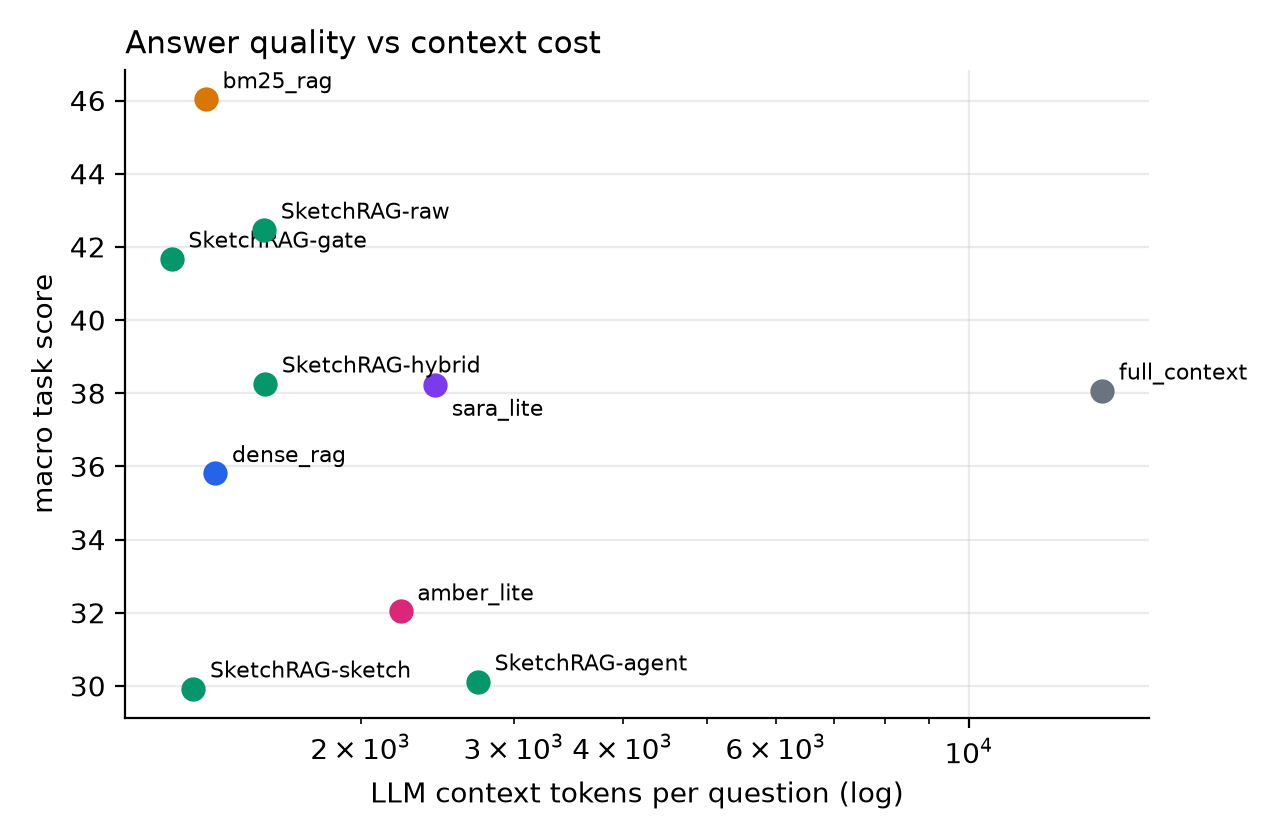

In [15]:
display(Image(filename=str(d.ROOT / "report" / "figures" / "main_pareto.png"), width=720))

### Is the gate calibrated?

In [16]:
c = d.gate_calibration(run)
print(f"gate fired on {c['fired']} of {c['n']} questions ({c['fired'] / c['n']:.0%})")
print(f"  on those:  digest only {c['fired_sketch']:.1f}  ->  with raw evidence {c['fired_gate']:.1f}")
print(f"gate trusted the digest on {c['trusted']} questions")
print(f"  on those:  gate {c['trusted_gate']:.1f}  vs  always raw {c['trusted_raw']:.1f}  (little left to gain)")

gate fired on 190 of 350 questions (54%)
  on those:  digest only 30.0  ->  with raw evidence 51.5
gate trusted the digest on 160 questions
  on those:  gate 31.4  vs  always raw 32.2  (little left to gain)


## Takeaways

* The digest alone (29.9) loses exact facts. The Count-Min error bound tells us exactly when, and reading raw evidence
  only then gives 41.7, beating full context, dense RAG, SARA-lite and AMBER-lite with the fewest LLM tokens (1,213 / question).
* The gate's signal comes from the sketch guarantee, not from asking the LLM: the LLM-driven agent called a tool on
  only 30 of 350 questions and stayed at the digest-only level (30.1).
* BM25 RAG is still the strongest system overall (46.0), mostly on exact-match tasks.
* Limitation: on an 8.5M-word stream the memory stays at 1 to 4 MB, but recall drops to 0.29 against 0.44 for dense RAG.